# 3.1 Motion through pose composition

A fundamental aspect of the development of mobile robots is the motion itself. In an idyllic world, motion commands are sent to the robot locomotion system, which perfectly executes them and drives the robot to a desired location. However, this is not a trivial matter, as many sources of motion error appear:
- wheel slippage,
- inaccurate calibration,
- temporal response of motors,
- limited resolution during integration (time increments, measurement resolution), or
- unequal floor, among others.

These factors introduce uncertainty in the robot motion. Additionally, other constraints on the movement make its implementation difficult.

After executing a motion command, the robot would end up in a different position/orientation from the initial one. This particular chapter explores the concept of *robot's pose* used to represent these positions/orientations, and how we deal with it in a probabilistic context.

The pose itself can take multiple forms depending on the problem context:

- **2D location**: In a planar context we only need a 2D vector $\mathbf{r}=[x, y]^T$ to locate a robot against a point of reference, the origin $(0, 0).$
- **2D pose**: In most cases involving mobile robots, the location alone is insufficient. We need an additional parameter known as orientation or *bearing*. Therefore, a robot's pose is usually expressed as $\mathbf{x}=[x, y, \theta]^T=[\mathbf{r}, \theta]^T$ (see Fig. 1). *In the rest of the book, we mostly refer to this one.*
- **3D pose**: Although we will only mention it in passing, for robotics applications in the 3D space, *e.g.* UAVs or drones, not only a third axis $z$ is added, but to handle the orientation in a 3D environment we need 3 components, *i.e.* roll, pitch and yaw. This course is centered around planar mobile robots so we will not use this one, nevertheless most methods could be adapted to 3D environments.

In this chapter we will explore how to use the **composition of poses** to express poses in a certain reference system. Concretely, given a robot pose expressed in an arbitrary reference frame and the motion increment it has experienced (expressed w.r.t. that pose), the composition permits us to retrieve the new robot pose in said reference frame. The next two chapters describe two probabilistic methods for dealing with the uncertainty inherent to robot motion, namely the **velocity-based** motion model and the **odometry-based** one.

# Notebook context: move that robot!

The figure below shows a Giraff robot, equipped with a rig of RGB-D sensors and a 2D laser scanner. The robot is gathering information from said sensors to collect a dataset. Datasets are useful to train and test new techniques for navigation, perception, etc. However, if the robot remains static, the dataset will only contain information about the part of the room that it is currently inspecting, so, we need to move it!

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_motion/images/robot_giraff_mapir.jpg" alt="" width="400px">
</figure>

Your task in this notebook will be to command the robot to move through the environment and calculate its new position after executing a motion command. Let's go!

In [1]:
# In case of using Google Colab, mount Google Drive and enable interactive plots
try:
    from google.colab import drive, output
    drive.mount('/content/drive')
    # Change directory to this chapter's folder in your Drive copy of the course repo:
    %cd '/content/drive/MyDrive/Colab Notebooks/uma_robotics_2027/Chapter 03. Robot motion'
    %pip install -q ipympl
    # Make matplotlib detect the freshly installed ipympl backend:
    from matplotlib.backends.registry import backend_registry
    backend_registry.__init__()
    output.enable_custom_widget_manager()
except ImportError:
    pass

%matplotlib inline

# IMPORTS

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, clear_output
import time

import sys
sys.path.append("..")
from utils.DrawRobot import DrawRobot
from utils.tcomp import tcomp

## <span style="color:green">OPTIONAL</span>

<span style="color:green">In the Robot motion lecture, we started talking about *Differential drive* motion systems. Include as many cells as needed to introduce the background that you find interesting about it and some code illustrating some related aspects, for example, a code computing and plotting the *Instantaneous Center of Rotation (ICR)* according to a number of given parameters.</span>

### Differential drive and the instantaneous center of rotation

A differential-drive robot has two independently driven wheels separated by a distance $l$. With wheel radii $r_l,r_r$ and angular wheel speeds $\omega_l,\omega_r$, their linear speeds are $v_l=r_l\omega_l$ and $v_r=r_r\omega_r$. Assuming rolling without slipping, the midpoint of the axle has forward speed and yaw rate

$$v_P=\frac{v_l+v_r}{2},\qquad \omega=\frac{v_r-v_l}{l}. $$

If $\omega\ne 0$, the robot moves instantaneously on a circle about the **instantaneous center of rotation** (ICR), located at signed distance $R=v_P/\omega=l(v_l+v_r)/[2(v_r-v_l)]$ along the robot's local left axis. For world pose $(x,y,\theta)$, this gives $\mathrm{ICR}=(x-R\sin\theta,\ y+R\cos\theta)$. The sign of $R$ tells us which side the ICR is on. If $v_l=v_r$, the robot moves straight and the ICR lies at infinity; if $v_l=-v_r$, the midpoint stays in place and the robot rotates about itself.

For constant wheel speeds during an interval $\Delta t$, the displacement **in the initial robot frame** is

$$\Delta x=R\sin(\omega\Delta t),\qquad \Delta y=R[1-\cos(\omega\Delta t)],\qquad \Delta\theta=\omega\Delta t.$$

When $\omega=0$, use the limit $(\Delta x,\Delta y,\Delta\theta)=(v_P\Delta t,0,0)$. This local displacement can then be composed with the initial pose to obtain the final pose in world coordinates. The following experiment illustrates the ICR and the resulting path; try $v_l=v_r$ and $v_l=-v_r$ too.

ICR = (-0.250, 0.433) m; signed radius R = 0.500 m
Wheel angular speeds: left=2.000, right=6.000 rad/s
v_P = 0.400 m/s, omega = 0.800 rad/s
Local pose increment: [0.4997868  0.51459976 1.6       ]
Final world pose: [0.17552819 0.69554987 2.12359878]


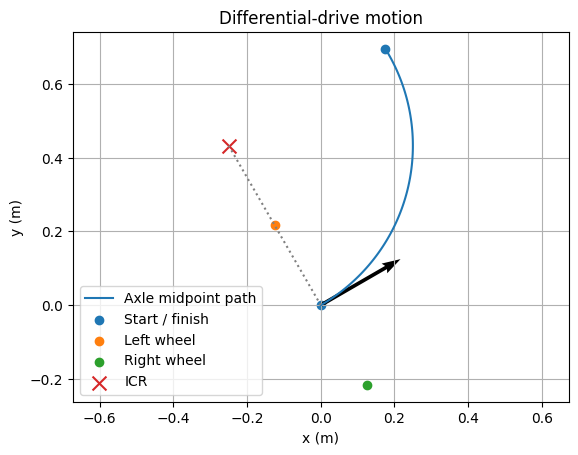

In [2]:
l = 0.5
wheel_radius = 0.1
v_l, v_r = 0.2, 0.6
x, y, theta = 0.0, 0.0, np.pi / 6
Delta_t = 2.0

v_P = (v_l + v_r) / 2
omega = (v_r - v_l) / l
times = np.linspace(0, Delta_t, 100)

if abs(omega) > 1e-12:
    R = v_P / omega
    icr_x, icr_y = x - R * np.sin(theta), y + R * np.cos(theta)
    x_path = x + R * (np.sin(theta + omega * times) - np.sin(theta))
    y_path = y - R * (np.cos(theta + omega * times) - np.cos(theta))
    local_increment = np.vstack([R * np.sin(omega * Delta_t),
                                 R * (1 - np.cos(omega * Delta_t)),
                                 omega * Delta_t])
    print(f"ICR = ({icr_x:.3f}, {icr_y:.3f}) m; signed radius R = {R:.3f} m")
else:
    x_path = x + v_P * np.cos(theta) * times
    y_path = y + v_P * np.sin(theta) * times
    local_increment = np.vstack([v_P * Delta_t, 0.0, 0.0])
    print("ICR at infinity: straight-line motion")

final_pose = tcomp(np.vstack([x, y, theta]), local_increment)
print(f"Wheel angular speeds: left={v_l / wheel_radius:.3f}, right={v_r / wheel_radius:.3f} rad/s")
print(f"v_P = {v_P:.3f} m/s, omega = {omega:.3f} rad/s")
print(f"Local pose increment: {local_increment.ravel()}")
print(f"Final world pose: {final_pose.ravel()}")

fig, ax = plt.subplots()
ax.plot(x_path, y_path, label="Axle midpoint path")
ax.scatter([x, final_pose[0, 0]], [y, final_pose[1, 0]], label="Start / finish")
ax.scatter(x - l / 2 * np.sin(theta), y + l / 2 * np.cos(theta), label="Left wheel")
ax.scatter(x + l / 2 * np.sin(theta), y - l / 2 * np.cos(theta), label="Right wheel")
ax.quiver(x, y, 0.25 * np.cos(theta), 0.25 * np.sin(theta),
          angles="xy", scale_units="xy", scale=1)
if abs(omega) > 1e-12:
    ax.scatter(icr_x, icr_y, marker="x", s=100, label="ICR")
    ax.plot([x, icr_x], [y, icr_y], ":", color="gray")
ax.set(xlabel="x (m)", ylabel="y (m)", title="Differential-drive motion")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(True)
ax.legend()
plt.show()

<span style="color:green">***END OF OPTIONAL PART***</span>

## 3.1 Pose composition <a id="pose_composition"></a>

The composition of poses is a tool that permits us to express the *final* pose of a robot in an arbitrary coordinate system. Given an initial pose $\textbf{x}_1$ and a pose differential $\Delta \textbf{x}$ (pose increment), *i.e.* how much the robot has moved during an interval of time, the final pose $\textbf{x}_2$ can be computed using the **composition of poses** function (see Fig.1):

$$
    \textbf{x}_1 =
        \begin{bmatrix}
            x_1 \\ y_1 \\ \theta_1
        \end{bmatrix}, \, \, \,
    \Delta \textbf{x} =
        \begin{bmatrix}
            \Delta x \\ \Delta y \\ \Delta \theta
        \end{bmatrix}
$$

$$
    \textbf{x}_2 = \begin{bmatrix}
            x \\ y \\ \theta
        \end{bmatrix}
        = \textbf{x}_1 \oplus \Delta \textbf{x}
        = \begin{bmatrix}
            x_1 + \Delta x \cos \theta_1 - \Delta y \sin \theta_1 \\
            y_1 + \Delta x \sin \theta_1 + \Delta y \cos \theta_1 \\
            \theta_1 + \Delta \theta
          \end{bmatrix}
$$

<center><br /><figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_motion/images/pose-composition.png" alt="" width="400px">
  <figcaption>Fig. 1: Example of an initial 2D robot pose ($p_1$) and its resultant pose ($p_2$) after completing a motion ($\Delta p$).</figcaption>
</figure></center>

The differential $\Delta \textbf{x}$, although we are using it as control in this exercise, is normally calculated given the robot's locomotion or sensed by the wheel encoders.

You are provided with a function called `pose_2 = tcomp(pose_1,u)` that applies the composition of poses to pose `pose_1` and pose increment `u` and returns the new pose `pose_2`. Below you have a code cell to play with it.

Initial pose:
[[0]
 [0]
 [0]]
Pose increment:
[[2.        ]
 [2.        ]
 [1.57079633]]
New pose after applying tcomp:
[[2.        ]
 [2.        ]
 [1.57079633]]


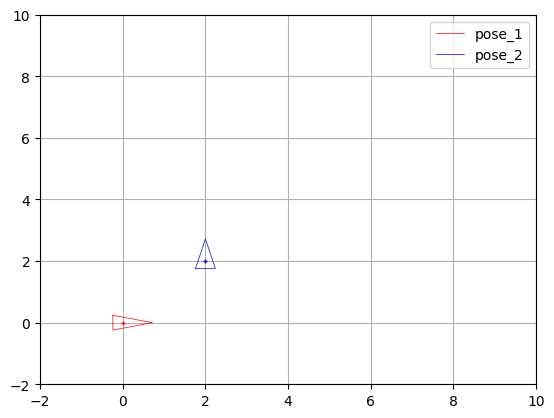

In [3]:
# Pose increments' playground!

# You can modify pose and increment here to experiment
pose_1 = np.vstack([0, 0, 0])  # Initial pose
u = np.vstack([2, 2, np.pi/2])  # Pose increment
pose_2 = tcomp(pose_1, u) # Pose after executing the motion

# NUMERICAL RESULTS
print(f"Initial pose:\n{pose_1}")
print(f"Pose increment:\n{u}")
print(f"New pose after applying tcomp:\n{pose_2}")

# VISUALIZATION
fig, ax = plt.subplots()
plt.grid('on')
plt.xlim((-2, 10))
plt.ylim((-2, 10))
h1 = DrawRobot(fig, ax, pose_1);
h2 = DrawRobot(fig, ax, pose_2, color='blue')
plt.legend([h1[0],h2[0]],['pose_1','pose_2']);

## <span style="color:green">OPTIONAL</span>

<span style="color:green">Implement your own methods to compute the composition of two poses, as well as the inverse composition. Include some examples of their utilization, also incorporating plots.</span>

### Composición, inversa y composición inversa implementadas a mano

Además de la composición $\mathbf{x}_1 \oplus \Delta\mathbf{x}$ definida arriba, se usan otras dos operaciones:

- **Pose inversa** $\ominus\mathbf{x}$: describe el origen del marco global visto desde el marco local de $\mathbf{x}$. Es el elemento que deshace la composición: $\mathbf{x} \oplus (\ominus\mathbf{x}) = (\ominus\mathbf{x}) \oplus \mathbf{x} = [0, 0, 0]^T$.

$$
\ominus\mathbf{x} =
\begin{bmatrix}
-x\cos\theta - y\sin\theta \\
\phantom{-}x\sin\theta - y\cos\theta \\
-\theta
\end{bmatrix}
$$

- **Composición inversa** $\mathbf{x}_2 \ominus \mathbf{x}_1 = (\ominus\mathbf{x}_1) \oplus \mathbf{x}_2$: dadas dos poses expresadas en el mismo marco global, devuelve $\mathbf{x}_2$ expresada en el marco de $\mathbf{x}_1$, es decir, el incremento local $\Delta\mathbf{x}$ que lleva de $\mathbf{x}_1$ a $\mathbf{x}_2$ (lo que haría un modelo de odometría a partir de dos poses consecutivas):

$$
\mathbf{x}_2 \ominus \mathbf{x}_1 =
\begin{bmatrix}
\phantom{-}(x_2 - x_1)\cos\theta_1 + (y_2 - y_1)\sin\theta_1 \\
-(x_2 - x_1)\sin\theta_1 + (y_2 - y_1)\cos\theta_1 \\
\theta_2 - \theta_1
\end{bmatrix}
$$

Es decir, se rota la diferencia de posiciones por $\mathbf{R}(\theta_1)^T$; restar coordenadas globales sin rotarlas no da el incremento local. En todas las funciones el ángulo se normaliza a $(-\pi, \pi]$ con `arctan2`. Primero se comprueba que las funciones coinciden con las de `utils` (`tcomp`, `inv_tcomp`, `tinv`) sobre poses aleatorias y que cumplen las propiedades anteriores; después se ilustran con tres ejemplos.

In [4]:
from utils.tcomp import inv_tcomp
from utils.tinv import tinv

def wrap_angle(angle):
    return np.arctan2(np.sin(angle), np.cos(angle))

def compose(p1, p2):
    """p1 (+) p2: pose p2, expressed in the frame of p1, transformed to the frame where p1 is expressed."""
    x1, y1, th1 = p1.ravel()
    x2, y2, th2 = p2.ravel()
    c, s = np.cos(th1), np.sin(th1)
    return np.vstack([x1 + c * x2 - s * y2,
                      y1 + s * x2 + c * y2,
                      wrap_angle(th1 + th2)])

def inverse(p):
    """(-) p: origin of the reference frame seen from pose p."""
    x, y, th = p.ravel()
    c, s = np.cos(th), np.sin(th)
    return np.vstack([-c * x - s * y,
                      s * x - c * y,
                      wrap_angle(-th)])

def inverse_compose(p1, p2):
    """p2 (-) p1 = ((-) p1) (+) p2: pose p2 expressed in the frame of p1."""
    return compose(inverse(p1), p2)

def same_pose(a, b, tol=1e-9):
    return np.allclose(a[:2], b[:2], atol=tol) and abs(wrap_angle(a[2, 0] - b[2, 0])) < tol

# Checks against the provided utilities and the algebraic properties
rng = np.random.default_rng(0)
origin = np.zeros((3, 1))
for _ in range(1000):
    a = rng.uniform([-10, -10, -np.pi], [10, 10, np.pi]).reshape(3, 1)
    b = rng.uniform([-10, -10, -np.pi], [10, 10, np.pi]).reshape(3, 1)
    c = rng.uniform([-10, -10, -np.pi], [10, 10, np.pi]).reshape(3, 1)
    assert same_pose(compose(a, b), tcomp(a, b))
    assert same_pose(inverse_compose(a, b), inv_tcomp(a, b))
    assert same_pose(inverse(a), tinv(a))
    assert same_pose(compose(a, inverse(a)), origin) and same_pose(compose(inverse(a), a), origin)
    assert same_pose(compose(a, inverse_compose(a, b)), b)
    assert same_pose(compose(compose(a, b), c), compose(a, compose(b, c)))
print("All checks passed: compose == tcomp, inverse_compose == inv_tcomp, inverse == tinv,")
print("p (+) ((-) p) = 0, p1 (+) (p2 (-) p1) = p2 and (+) is associative.")

p1, delta = np.vstack([1., 2., np.pi/2]), np.vstack([3., 0., -np.pi/2])
print(f"\n(1, 2, pi/2) (+) (3, 0, -pi/2) = {compose(p1, delta).ravel().round(3)}")

All checks passed: compose == tcomp, inverse_compose == inv_tcomp, inverse == tinv,


p (+) ((-) p) = 0, p1 (+) (p2 (-) p1) = p2 and (+) is associative.

(1, 2, pi/2) (+) (3, 0, -pi/2) = [1. 5. 0.]


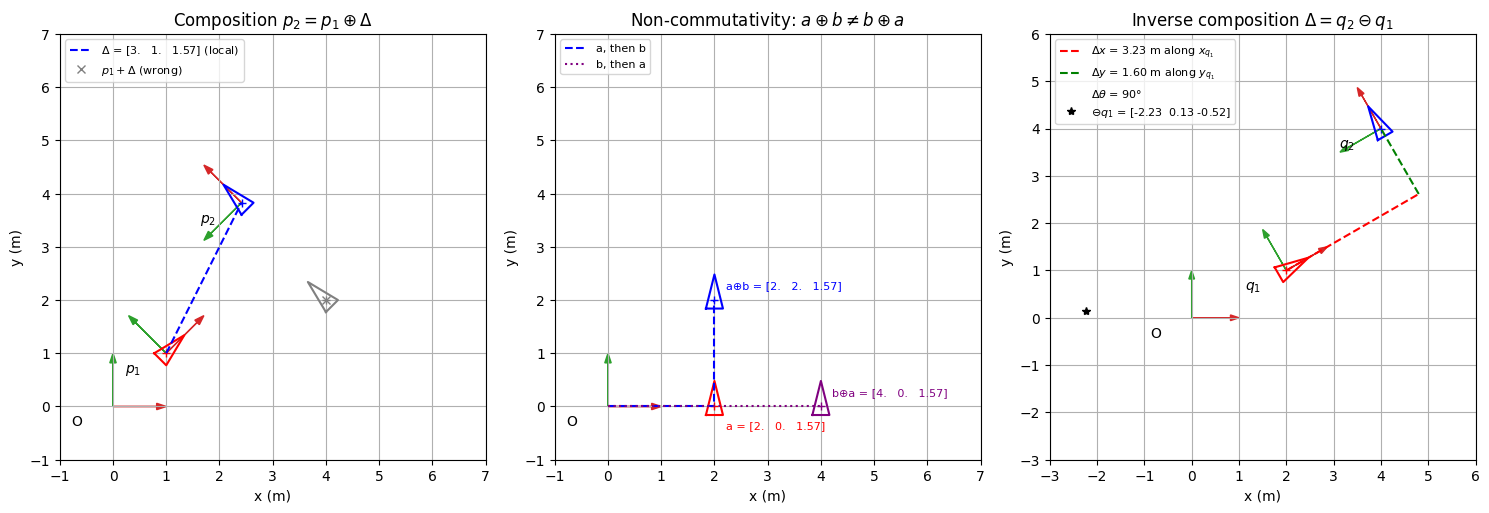

(a) p1 (+) delta = [2.414 3.828 2.356]   vs   naive sum p1 + delta = [4.    2.    2.356]
(b) a (+) b = [2.    2.    1.571]   vs   b (+) a = [4.    0.    1.571]
(c) q2 (-) q1 = [3.232 1.598 1.571];   q1 (+) (q2 (-) q1) = [4.    4.    2.094] = q2


In [5]:
def draw_frame(ax, p, label, length=1.0):
    """Draws the local axes of pose p (x in red, y in green) and its label."""
    x, y, th = p.ravel()
    arrow = dict(head_width=0.12, length_includes_head=True)
    ax.arrow(x, y, length * np.cos(th), length * np.sin(th), color='tab:red', **arrow)
    ax.arrow(x, y, -length * np.sin(th), length * np.cos(th), color='tab:green', **arrow)
    ax.annotate(label, (x, y), textcoords='offset points', xytext=(-30, -14))

def setup_axes(ax, title, lims=(-1, 7)):
    plt.sca(ax)  # DrawRobot sizes the robot using the current axes
    ax.set(xlim=lims, ylim=lims, title=title, xlabel='x (m)', ylabel='y (m)')
    ax.set_aspect('equal')
    ax.grid(True)
    draw_frame(ax, origin, 'O')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# (a) Composition: the increment is expressed in the frame of p1, not in the global one
p1, delta = np.vstack([1., 1., np.pi/4]), np.vstack([3., 1., np.pi/2])
p2 = compose(p1, delta)
naive = p1 + delta
setup_axes(axes[0], 'Composition $p_2 = p_1 \\oplus \\Delta$')
draw_frame(axes[0], p1, '$p_1$')
draw_frame(axes[0], p2, '$p_2$')
DrawRobot(fig, axes[0], p1, linewidth=1.5)
DrawRobot(fig, axes[0], p2, color='blue', linewidth=1.5)
DrawRobot(fig, axes[0], naive, color='gray', linewidth=1.5)
axes[0].plot(*np.hstack([p1[:2], p2[:2]]), 'b--', label=f'$\\Delta$ = {delta.ravel().round(2)} (local)')
axes[0].plot(*naive[:2], 'x', color='gray', label='$p_1 + \\Delta$ (wrong)')
axes[0].legend(loc='upper left', fontsize=8)

# (b) The composition is not commutative
a, b = np.vstack([2., 0., np.pi/2]), np.vstack([2., 0., 0.])
ab, ba = compose(a, b), compose(b, a)
setup_axes(axes[1], 'Non-commutativity: $a \\oplus b \\neq b \\oplus a$')
for pose, color, name, offset in [(a, 'red', 'a', (8, -16)), (ab, 'blue', 'a⊕b', (8, 8)), (ba, 'purple', 'b⊕a', (8, 8))]:
    DrawRobot(fig, axes[1], pose, color=color, linewidth=1.5)
    axes[1].annotate(f'{name} = {pose.ravel().round(2)}', pose[:2, 0], textcoords='offset points',
                     xytext=offset, color=color, fontsize=8)
axes[1].plot([0, 2, 2], [0, 0, 2], 'b--', label='a, then b')
axes[1].plot([0, 2, 4], [0, 0, 0], ':', color='purple', label='b, then a')
axes[1].legend(loc='upper left', fontsize=8)

# (c) Inverse composition: relative motion between two global poses
q1, q2 = np.vstack([2., 1., np.pi/6]), np.vstack([4., 4., 2*np.pi/3])
rel = inverse_compose(q1, q2)
setup_axes(axes[2], 'Inverse composition $\\Delta = q_2 \\ominus q_1$', lims=(-3, 6))
draw_frame(axes[2], q1, '$q_1$')
draw_frame(axes[2], q2, '$q_2$')
DrawRobot(fig, axes[2], q1, linewidth=1.5)
DrawRobot(fig, axes[2], q2, color='blue', linewidth=1.5)
# Decomposition of the relative motion along the local axes of q1
corner = compose(q1, np.vstack([rel[0, 0], 0., 0.]))
axes[2].plot(*np.hstack([q1[:2], corner[:2]]), 'r--', label=f'$\\Delta x$ = {rel[0, 0]:.2f} m along $x_{{q_1}}$')
axes[2].plot(*np.hstack([corner[:2], q2[:2]]), 'g--', label=f'$\\Delta y$ = {rel[1, 0]:.2f} m along $y_{{q_1}}$')
axes[2].plot([], [], ' ', label=f'$\\Delta\\theta$ = {np.degrees(rel[2, 0]):.0f}°')
axes[2].plot(*inverse(q1)[:2], 'k*', label=f'$\\ominus q_1$ = {inverse(q1).ravel().round(2)}')
axes[2].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

print(f"(a) p1 (+) delta = {p2.ravel().round(3)}   vs   naive sum p1 + delta = {naive.ravel().round(3)}")
print(f"(b) a (+) b = {ab.ravel().round(3)}   vs   b (+) a = {ba.ravel().round(3)}")
print(f"(c) q2 (-) q1 = {rel.ravel().round(3)};   q1 (+) (q2 (-) q1) = {compose(q1, rel).ravel().round(3)} = q2")

<span style="color:green">***END OF OPTIONAL PART***</span>

### **<span style="color:green"><b><i>ASSIGNMENT 1: Moving the robot by composing pose increments</i></b></span>**

Take a look at the `Robot()` class provided and its methods: the constructor, `step()` and `draw()`. Then, modify the main function in the next cell for the robot to describe a $8m \times 8m$ square path as seen in the figure below. You must take into account that:

- The robot starts in the bottom-left corner $(0, 0)$ heading north and
- moves at increments of $2 m$ each step.
- Every 4 steps, it will turn right.

**Example**


<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_motion/images/fig3-1-1.png" alt="">
  <figcaption>Fig. 2: Route of our robot.</figcaption>
</figure>

In [6]:
class Robot():
    '''Mobile robot implementation

        Attr:
            pose: Expected position of the robot
    '''
    def __init__(self, mean):
        self.pose = mean

    def step(self, u):
        self.pose = tcomp(self.pose, u)

    def draw(self, fig, ax):
        DrawRobot(fig, ax, self.pose)

In [7]:
def main(robot):

    # PARAMETERS INITIALIZATION
    num_steps = 15 # Number of robot motions
    turning = 4  # Number of steps for turning
    u = np.vstack([2., 0., 0.]) # Motion command (pose increment)
    angle_inc = -np.pi/2 # Angle increment

    # VISUALIZATION
    fig, ax = plt.subplots()
    plt.ion()
    plt.draw()
    plt.xlim((-2, 10))
    plt.ylim((-2, 10))
    plt.fill([2, 2, 6, 6],[2, 6, 6, 2],facecolor='lightgray', edgecolor='gray', linewidth=3)

    plt.grid()
    robot.draw(fig, ax)

    # MAIN LOOP
    for step in range(1,num_steps+1):

        # Check if the robot has to move in straight line or also has to turn
        # and accordingly set the third component (rotation) of the motion command
        if step % turning == 0:
            u[2] = angle_inc
        else:
            u[2] = 0

        # Execute the motion command
        robot.step(u)

        # VISUALIZATION
        robot.draw(fig, ax)
        clear_output(wait=True)
        display(fig)
        time.sleep(0.1)

    plt.close()

Execute the following code cell to **try your code**. The resulting figure must be the same as Fig. 2.

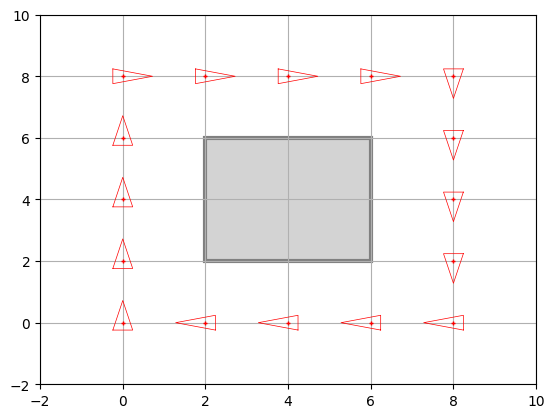

In [8]:
# RUN
initial_pose = np.vstack([0., 0., np.pi/2])
robot = Robot(initial_pose)
main(robot)

## 3.2 Considering noise

In the previous case, the robot motion was error-free. This is overly optimistic as in a real use case the conditions of the environment and the motion itself are a huge source of uncertainty.

To take into consideration such uncertainty, we will model the movement of the robot as a (multidimensional) Gaussian distribution $\Delta \mathbf{x} \sim N(\mu_{\Delta x},\Sigma_{\Delta x})$ where:

- The mean $\mu_{\Delta x}$ is still the pose differential in the previous exercise, that is $\Delta \mathbf{x}_{\text{given}}$.
- The covariance $\Sigma_{\Delta x}$ is a $3 \times 3$ matrix, which defines the amount of error at each step (time interval). It looks like this:

$$
\Sigma_{\Delta x}  =
        \begin{bmatrix}
            \sigma_x^2 & 0 & 0 \\
            0 & \sigma_y^2 & 0 \\
            0 & 0 & \sigma_\theta^2
        \end{bmatrix}
$$

To gain insight into the covariance matrix, let's suppose that we've commanded Giraff to move two meters forward, one to the left, and turn $\pi/2$ to the left a total of twenty times, and we've measured its final position. This is the result:

In [9]:
# Array of motion measurements [x_i,y_i,theta_i]
data = np.array([
    [1.9272377,  0.61826959, 1.56767043],
    [2.32512511, 1.00742,    1.5908133],
    [2.18640042, 0.98655067, 1.68010124],
    [1.98890723, 0.96641266, 1.5478623],
    [2.0729443,  0.82685635, 1.67115959],
    [1.975565,   1.20433306, 1.62406736],
    [1.88160001, 1.17310891, 1.54204513],
    [2.21991591, 0.92045473, 1.55294863],
    [1.79006882, 0.97170525, 1.60347324],
    [2.13932179, 1.17665025, 1.57022972],
    [1.89099453, 0.86546558, 1.52364342],
    [1.78903666, 0.93264142, 1.60133537],
    [2.05418773, 1.34436849, 1.58577607],
    [2.12027142, 1.15626879, 1.5552685],
    [2.04842395, 1.22015604, 1.58246969],
    [2.00209448, 0.77744971, 1.55656092],
    [2.06276761, 0.88401541, 1.62989382],
    [1.70384096, 1.12819609, 1.61440142],
    [1.84918712, 1.26022099, 1.50058668],
    [2.02138316, 1.12614774, 1.52156016]
])

### **<span style="color:green"><b><i>ASSIGNMENT 2: Calculating the covariance matrix</i></b></span>**

Complete the following code to compute the covariance matrix characterizing the motion uncertainty of the Giraff robot. Ask yourself what the values in the diagonal mean, and what happens if they increase/decrease.

*Hints: `np.var()`, `np.diag()`*

Covariance matrix:
[[0.02342594 0.         0.        ]
 [0.         0.03246639 0.        ]
 [0.         0.         0.00212976]]


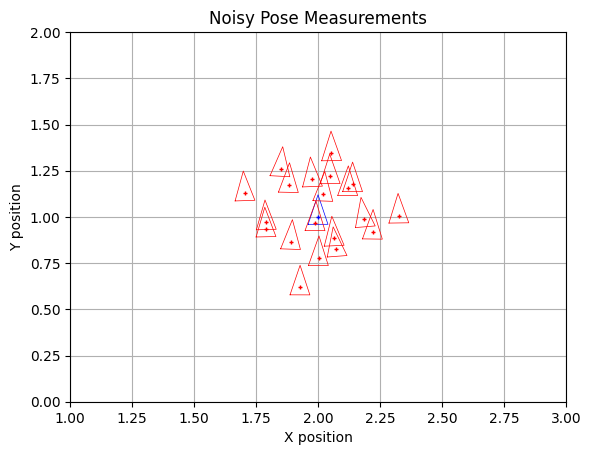

In [10]:
# Compute the covariance matrix (since there is no correlation, we only compute variances)
cov_x = np.var(data[:, 0])
cov_y = np.var(data[:, 1])
cov_theta = np.var(data[:, 2])

# Form the diagonal covariance matrix
covariance_matrix = np.diag([cov_x, cov_y, cov_theta])

# PRINT COVARIANCE MATRIX
print("Covariance matrix:")
print(covariance_matrix)

# VISUALIZATION
fig, ax = plt.subplots()
plt.xlim((1, 3))
plt.ylim((0, 2))
plt.grid('on')
# Commanded pose
DrawRobot(fig, ax, np.vstack([2, 1, np.pi/2]), color='blue')
# Noisy poses
for pose in data:
    DrawRobot(fig, ax, np.vstack([pose[0],pose[1],pose[2]]))
plt.xlabel('X position')
plt.ylabel('Y position')
plt.title('Noisy Pose Measurements')
plt.show()

<span style="color:blue">Expected results:</span>

```
Covariance matrix:
[[0.02342594 0.         0.        ]
 [0.         0.03246639 0.        ]
 [0.         0.         0.00212976]]
```

### **<span style="color:green"><b><i>ASSIGNMENT 3: Adding noise to the pose motion</i></b></span>**

Now, we are going to add a Gaussian noise to the motion, assuming that the incremental motion now follows the probability distribution:

$$
    \Delta \mathbf{x} = N(\Delta \mathbf{x}_{given}, \Sigma_{\Delta x})
    \textit{ with }
    \Sigma_{\Delta x}  =
        \begin{bmatrix}
            0.04 & 0 & 0 \\
            0 & 0.04 & 0 \\
            0 & 0 & 0.01
        \end{bmatrix}
    (\text{ units in }m^2 \text{ and } rad^2)
$$

For doing that, complete the `NoisyRobot()` class below, which is a child class of the previous `Robot()` one. Concretely, you have to:

- Complete this new class by adding some amount of noise to the movement (take a look at the `step()` method). *Hints: [`np.vstack()`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.vstack.html), [`stats.multivariate_normal.rvs()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.multivariate_normal.html)*.
- Remark that we have now two variables related to the robot pose:
  - `self.pose`, which represents the expected, *ideal* pose, and
  - `self.true_pose`, that stands for the actual pose after carrying out a noisy motion command.
- Along with the expected pose drawn in red (`self.pose`), in the `draw()` method plot the real pose of the robot (`self.true_pose`) in blue, which as commented is affected by noise.

Run the cell several times to see that the motion (and the path) is different each time. Try also with different values of the covariance matrix.

**Example**

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_motion/images/fig3-1-2.png" alt="">
  <figcaption>Fig. 3: Movement of our robot using pose compositions. <br/>
      Containing the expected poses (in red) and the true pose <br/> affected by noise (in blue)</figcaption>
</figure>

In [11]:
class NoisyRobot(Robot):
    """Mobile robot implementation. Its motion has a set amount of noise.

        Attr:
            pose: Inherited from Robot
            true_pose: Real robot pose, which has been affected by some amount of noise.
            covariance: Amount of error of each step.
    """
    def __init__(self, mean, covariance):
        super().__init__(mean)
        self.true_pose = mean
        self.covariance = covariance

    def step(self, step_increment):
        """Computes a single step of our noisy robot.

            super().step(...) updates the expected pose (without noise)
            Generate a noisy increment based on step_increment and self.covariance.
            Then this noisy increment is applied to self.true_pose
        """
        super().step(step_increment)
        true_step = np.vstack(stats.multivariate_normal.rvs(mean=step_increment.ravel(), cov=self.covariance))
        self.true_pose = tcomp(self.true_pose, true_step)

    def draw(self, fig, ax):
        super().draw(fig, ax)
        DrawRobot(fig, ax, self.true_pose, color='blue')

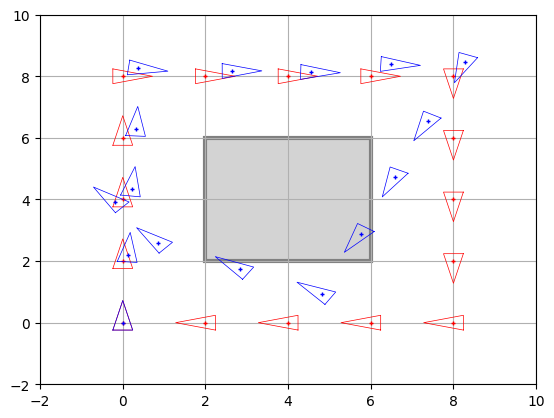

In [12]:
# RUN
initial_pose = np.vstack([0., 0., np.pi/2])
cov = np.diag([0.04, 0.04, 0.01])

robot = NoisyRobot(initial_pose, cov)
main(robot)

### Experimento: varias ejecuciones y distintas matrices de covarianza

El enunciado pide ejecutar varias veces el robot ruidoso y probar otros valores de $\Sigma_{\Delta x}$. Para poder comparar las ejecuciones lado a lado, se simula el mismo recorrido cuadrado de `main()` (15 pasos, giro a la derecha cada 4) sin animación, reutilizando la clase `NoisyRobot`. La línea roja discontinua es la trayectoria esperada y la azul, la real:

- **Fila superior:** tres ejecuciones con la covarianza del enunciado, $\mathrm{diag}(0.04, 0.04, 0.01)$.
- **Fila inferior:** poco ruido, $\mathrm{diag}(0.001, 0.001, 0.0001)$; solo ruido de traslación, $\mathrm{diag}(0.04, 0.04, \approx 0)$; y solo ruido de rotación, $\mathrm{diag}(\approx 0, \approx 0, 0.01)$. Las varianzas «nulas» valen $10^{-12}$ porque `multivariate_normal` necesita una matriz de covarianza no singular.

Después, una simulación de Monte Carlo (200 ejecuciones por covarianza, incluyendo también mucho ruido angular, $\mathrm{diag}(0.04, 0.04, 0.1)$) mide el error medio de posición tras cada paso. Se fija la semilla para que los resultados comentados sean reproducibles.

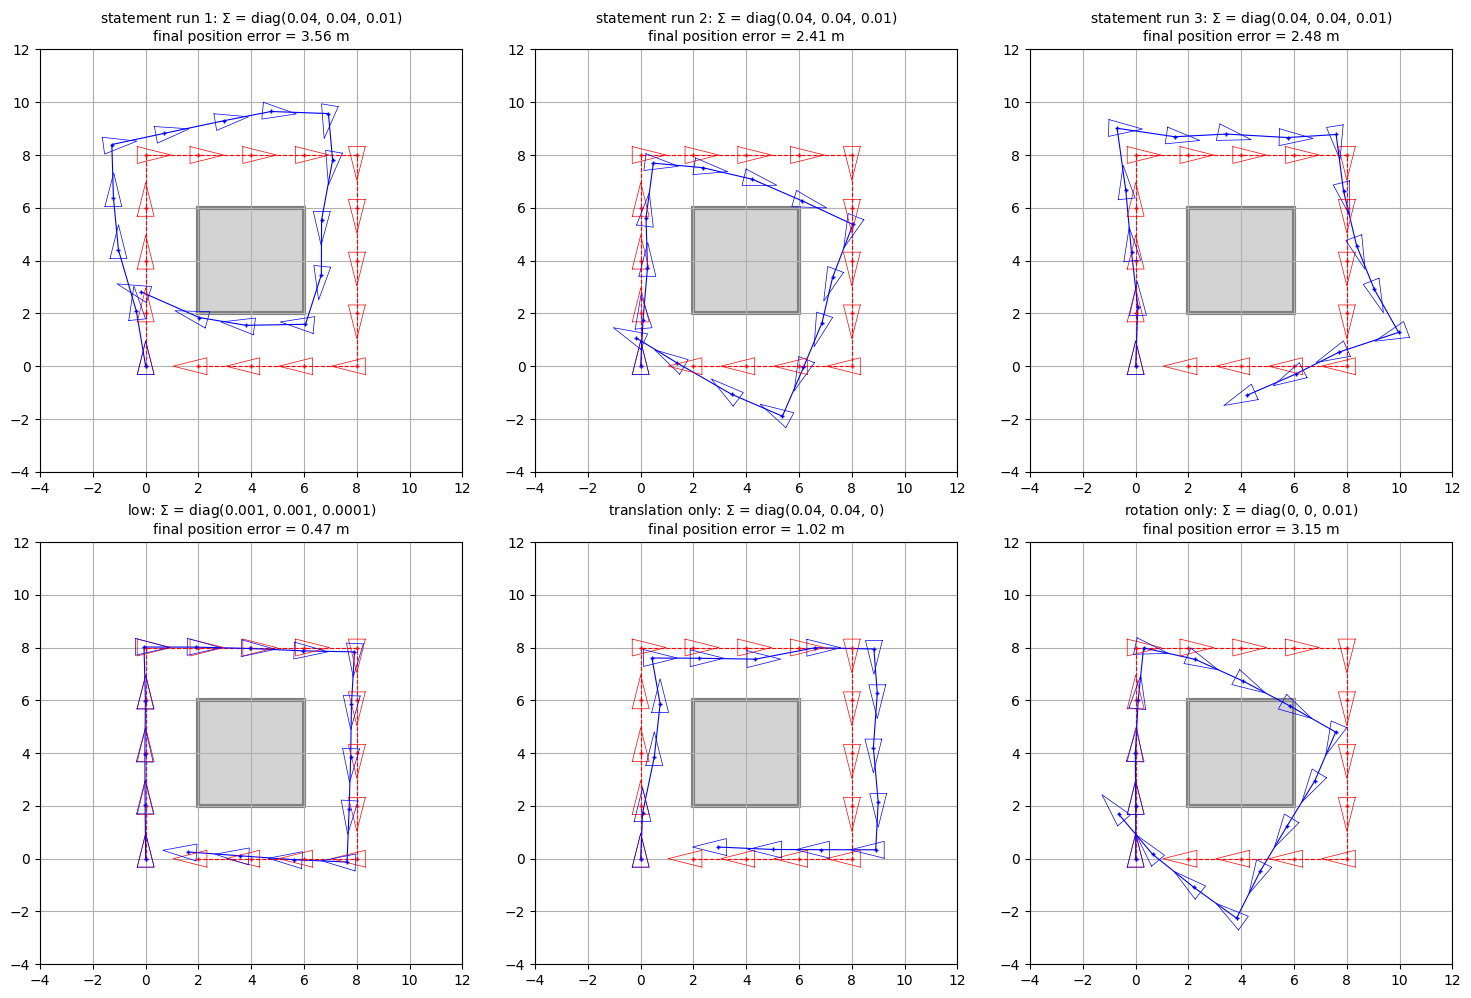

In [13]:
def simulate(robot, num_steps=15, turning=4, angle_inc=-np.pi/2):
    '''Runs the square path of main() without animation and returns the expected and true poses (3 x N+1).'''
    u = np.vstack([2., 0., 0.])
    expected, true = [robot.pose], [robot.true_pose]
    for step in range(1, num_steps + 1):
        u[2] = angle_inc if step % turning == 0 else 0
        robot.step(u)
        expected.append(robot.pose)
        true.append(robot.true_pose)
    return np.hstack(expected), np.hstack(true)

eps = 1e-12
covariances = {
    'low': np.diag([0.001, 0.001, 0.0001]),
    'statement': np.diag([0.04, 0.04, 0.01]),
    'translation only': np.diag([0.04, 0.04, eps]),
    'rotation only': np.diag([eps, eps, 0.01]),
    'high rotation': np.diag([0.04, 0.04, 0.1]),
}
initial_pose = np.vstack([0., 0., np.pi/2])
np.random.seed(0)

cases = [('statement', 'run 1'), ('statement', 'run 2'), ('statement', 'run 3'),
         ('low', ''), ('translation only', ''), ('rotation only', '')]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (name, run) in zip(axes.ravel(), cases):
    expected, true = simulate(NoisyRobot(initial_pose, covariances[name]))
    plt.sca(ax)  # DrawRobot sizes the robot using the current axes
    ax.set(xlim=(-4, 12), ylim=(-4, 12), aspect='equal')
    ax.grid(True)
    ax.fill([2, 2, 6, 6], [2, 6, 6, 2], facecolor='lightgray', edgecolor='gray', linewidth=3)
    ax.plot(expected[0], expected[1], 'r--', linewidth=0.8)
    ax.plot(true[0], true[1], 'b-', linewidth=0.8)
    for k in range(expected.shape[1]):
        DrawRobot(fig, ax, expected[:, [k]])
        DrawRobot(fig, ax, true[:, [k]], color='blue')
    final_error = np.linalg.norm(expected[:2, -1] - true[:2, -1])
    variances = ', '.join(f'{v:g}' if v > eps else '0' for v in np.diag(covariances[name]))
    ax.set_title(f"{name}{' ' + run if run else ''}: $\\Sigma$ = diag({variances})\nfinal position error = {final_error:.2f} m", fontsize=10)
plt.tight_layout()
plt.show()

        covariance | mean error after 4 / 8 / 15 steps (m) | max error after 15 steps (m)
               low |       0.09   0.18   0.27            |   0.65
         statement |       0.75   1.78   2.36            |   6.79
  translation only |       0.52   0.73   0.96            |   2.66


     rotation only |       0.57   1.54   2.31            |   6.76
     high rotation |       2.06   5.18   6.87            |  18.33


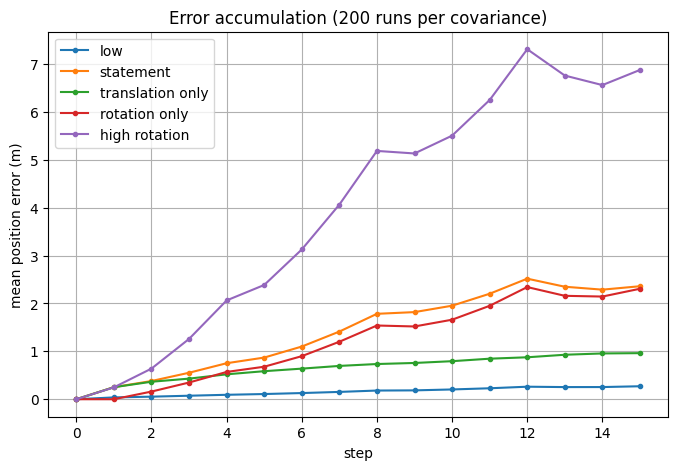

In [14]:
# Monte Carlo: average distance between expected and true position after each step (200 runs per covariance)
num_runs = 200
fig, ax = plt.subplots(figsize=(8, 5))
print(f"{'covariance':>18} | mean error after 4 / 8 / 15 steps (m) | max error after 15 steps (m)")
for name, cov in covariances.items():
    errors = np.array([np.linalg.norm(np.subtract(*simulate(NoisyRobot(initial_pose, cov)))[:2], axis=0)
                       for _ in range(num_runs)])
    mean_error = errors.mean(axis=0)
    ax.plot(mean_error, 'o-', markersize=3, label=name)
    print(f"{name:>18} | {mean_error[4]:10.2f} {mean_error[8]:6.2f} {mean_error[15]:6.2f}            | {errors[:, -1].max():6.2f}")
ax.set(xlabel='step', ylabel='mean position error (m)', title=f'Error accumulation ({num_runs} runs per covariance)')
ax.grid(True)
ax.legend()
plt.show()

**Observaciones:**

- Cada ejecución con la covarianza del enunciado da una trayectoria real distinta, porque en cada paso se muestrea un incremento ruidoso nuevo; la trayectoria esperada es siempre la misma.
- El error **se acumula**: el error medio de posición crece con el número de pasos (con la covarianza del enunciado, unos $0.75$ m tras 4 pasos, $1.8$ m tras 8 y $2.4$ m tras 15), porque cada incremento ruidoso se compone sobre la pose real anterior, que ya era errónea, y nada lo corrige. La curva no es estrictamente creciente porque el recorrido es cerrado: tras los giros, parte de la deriva puede acercar de nuevo la pose real a la esperada.
- Cuanto mayores son las varianzas, mayor es la dispersión: con poco ruido el robot acaba, de media, a unos $0.3$ m de la pose esperada y con mucho ruido angular, a casi $7$ m.
- **El ruido angular es el término dominante**: solo con ruido de rotación el error final ($\approx 2.3$ m) es casi igual que con la covarianza completa y más del doble que solo con ruido de traslación ($\approx 1$ m), aunque $\sigma_\theta = 0.1$ rad parezca pequeño. Un error de orientación rota todos los avances de 2 m posteriores, de modo que el error de posición sigue creciendo; un error de traslación solo desplaza el robot una vez. Por eso, con ruido solo angular el error tras el primer paso es nulo: el giro erróneo se nota a partir del paso siguiente.

### <font color="blue"><b><i>Thinking about it (1)</i></b></font>

Now that you are an expert in retrieving the pose of a robot after carrying out a motion command defined as a pose increment, **answer the following questions**:

- Why are the expected (red) and true (blue) poses different?

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>La pose esperada (roja) se obtiene componiendo siempre el incremento nominal [2, 0, Δθ]<sup>T</sup>, mientras que la pose real (azul) compone en cada paso un incremento muestreado de N(Δ<b>x</b><sub>given</sub>, Σ<sub>Δx</sub>), que modela el deslizamiento de las ruedas, la mala calibración, etc. Además, el error se acumula: cada incremento ruidoso se compone sobre la pose real anterior, que ya era errónea, y un pequeño error de orientación hace que todos los avances posteriores se realicen en una dirección equivocada. Como no hay ningún sensor externo que corrija la estimación (navegación a estima o <i>dead reckoning</i>), la discrepancia tiende a crecer con el número de pasos.</i></p>

- In which scenario could they be the same?

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Solo si el movimiento fuese ideal, es decir, si Σ<sub>Δx</sub> = <b>0</b>: sin deslizamiento, con calibración perfecta, suelo uniforme y motores que ejecutan exactamente la orden. En ese caso <code>NoisyRobot</code> se comporta igual que <code>Robot</code>. También coinciden en el instante inicial, porque ambas parten de la misma pose conocida (0, 0, π/2). Con ruido continuo, la probabilidad de que una muestra coincida exactamente con la media es nula; en un robot real solo podríamos acercar la estimación a la pose real corrigiéndola con sensores externos (localización), no hacerlas idénticas.</i></p>
    
- How do the values in the covariance matrix $\Sigma_{\Delta x}$ affect the robot motion?

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>La diagonal contiene las varianzas del error de cada componente del incremento, expresadas en el marco local del robot: σ<sub>x</sub><sup>2</sup> es el error longitudinal (avanzar más o menos de 2 m), σ<sub>y</sub><sup>2</sup> el error lateral y σ<sub>θ</sub><sup>2</sup> el error de giro. Con Σ<sub>Δx</sub> = diag(0.04, 0.04, 0.01), las desviaciones típicas son 0.2 m (un 10 % del paso) y 0.1 rad (≈ 5.7°). Si los valores aumentan, las muestras se dispersan más y la trayectoria real se aleja antes y más de la esperada; si disminuyen, ambas trayectorias se parecen más. El término angular es especialmente crítico: un error δθ desplaza lateralmente unos d·δθ cada avance posterior de longitud d, por lo que el error de posición crece a lo largo del recorrido aunque σ<sub>θ</sub> sea pequeño. Los ceros fuera de la diagonal indican que los errores de cada componente se suponen independientes.</i></p>

## <font color="orange"><b><i>AI Appendix</i></b></font>

### A.1 How I used AI
- **Model/tool:**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Un asistente de programación basado en IA generativa (Devin con Claude Opus 5.5)</i></p>
- **What I asked AI to help with (bullets):**
  <div style="margin: 4px 0px 6px 5px; color:#2DD4BF; font-style: italic"><ul><li>Ayuda para resolver los ejercicios del notebook y comprobar los resultados.</li><li>Explicaciones de los conceptos de la práctica (composición de poses, covarianza y ruido gaussiano).</li></ul></div>
- **Best prompt I used (paste):**
  
- **What I kept vs. changed from the AI output:**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>He ido revisando las distintas secciones de código y ajustándolas para que se acercaran a lo requerido</i></p>

### A.2 AI review
Ask one generative AI to review your memo using this prompt:

```
Act as a technical reviewer of this robotics notebook. Read my memo and return exactly 5 bullet points:

- two on theory (key ideas),
- two on practice (relevant programming concepts of Python used, not particular functions or variables),
- one on how to improve the code (most critical aspect: limitations, parameter choices, runtime/robustness, possible bugs).

Keep each bullet ≤15 words and make them specific to my work.
```

Paste its **5** items here:

*AI used for the review: an AI coding assistant.*

- **(Theory 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>La composición ⊕ rota el incremento local por θ; no equivale a sumar poses.</i></p>
- **(Theory 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>El ruido compuesto paso a paso acumula error, y el angular domina la deriva.</i></p>
- **(Practice 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Herencia: <code>NoisyRobot</code> reutiliza <code>Robot.step()</code> con <code>super()</code> y añade la pose real.</i></p>
- **(Practice 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Arrays NumPy: poses como columnas <code>(3, 1)</code>; <code>ravel</code>/<code>vstack</code> adaptan formas entre funciones.</i></p>
- **(Improvement)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Σ fija por paso no escala con distancia ni giro; usar un modelo de odometría.</i></p>

Finally, **do you agree with them?**, **would you have selected others?**
    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Estoy de acuerdo con los cinco puntos. Los dos teóricos resumen bien la práctica: la composición no es una suma y el error angular es el que más hace crecer la deriva, como muestra el experimento de Monte Carlo. La mejora propuesta también me parece la más relevante, porque con una Σ fija avanzar 2 m o 20 cm tendría la misma incertidumbre, lo cual no es realista; es justo lo que resuelven los modelos de movimiento basados en velocidad y en odometría de los siguientes notebooks. Como alternativa habría señalado que <code>main()</code> modifica in situ el mismo array <code>u</code> en cada paso: funciona porque <code>tcomp</code> no guarda referencias, pero es una fuente fácil de errores. Para la parte práctica habría destacado también el uso de una semilla fija para que los experimentos aleatorios sean reproducibles.</i></p>